<a href="https://colab.research.google.com/github/RamilML/ml-service/blob/main/Regression_SVM_RandomForest_YSA_kNN_Bayes_DecisionTree_SHAP_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# ======================================
# 1️⃣ KURULUM
# ======================================
!pip install -q scikit-learn pandas numpy openpyxl matplotlib

# ======================================
# 2️⃣ KÜTÜPHANELER
# ======================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# MODELLER
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

# ======================================
# 3️⃣ VERİYİ OKUMA
# ======================================
df = pd.read_csv('/content/sample_data/raw.csv', sep = r'\s+', header = None)
test_df = pd.read_csv('/content/sample_data/test.csv', sep = r'\s+', header = None)

featurs_cols = [f'enr_{i}' for i in range(1, 40)]
df.columns = ['k_inf', 'pppf'] + featurs_cols
test_df.columns = ['k_inf','pppf'] + featurs_cols
df = df.drop(columns='pppf')
test_df = test_df.drop(columns='pppf')
print(df.head())
print(df.columns.to_list())
print(df.shape)

y_train = df[['k_inf']]
X_train = df.drop(columns = ['k_inf'])

y_test = test_df[['k_inf']]
X_test = test_df.drop(columns = ['k_inf'])

print(df.info())
print(test_df.info())

# ======================================
# 4️⃣ TARGET ve FEATURES AYIRMA
# ======================================
target_col = "k_inf"
assert target_col in df.columns, f"'{target_col}' sütunu bulunamadı!"
X = df.drop(columns=[target_col])
y = df[target_col].astype(float)

# ======================================
# 5️⃣ ÖN İŞLEME: SAYISAL & KATEGORİK
# ======================================
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", ohe)
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])


y_train = y_train.values.ravel()
y_test = y_test.values.ravel()



     k_inf     enr_1     enr_2     enr_3     enr_4     enr_5     enr_6  \
0  1.32630  3.562615  1.112359  4.208065  1.412679  2.271031  3.950614   
1  1.34149  2.354766  1.047929  2.268974  4.637777  3.793194  2.859702   
2  1.33034  3.037997  4.719517  1.502280  3.644736  3.575727  1.337686   
3  1.35653  4.412804  2.220680  3.132738  1.327124  4.759890  2.882082   
4  1.30190  2.790669  0.798177  1.231750  1.977844  2.393930  4.738126   

      enr_7     enr_8     enr_9  ...    enr_30    enr_31    enr_32    enr_33  \
0  3.627032  4.600332  2.892000  ...  3.965987  4.030999  0.826347  2.088521   
1  4.361058  3.592485  2.594441  ...  2.228000  4.837370  2.846538  3.413201   
2  2.380347  4.503771  1.334796  ...  2.615278  3.757999  3.161658  4.996056   
3  3.663430  4.531524  2.679072  ...  3.899026  1.018926  4.379308  3.280298   
4  1.364743  3.391665  2.288784  ...  3.641512  1.564076  2.178406  2.754888   

     enr_34    enr_35    enr_36    enr_37    enr_38    enr_39  
0  4.08855

In [15]:

# ======================================
# 7️⃣ MODELLERİN TANIMI
# ======================================
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),


    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVR(kernel='rbf', C=10.0, epsilon=0.0005, gamma='scale')
    ),


    "YSA (MLP)": make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(128, 64),
            activation='relu',
            solver='adam',
            alpha=1e-5,
            max_iter=2000,
            tol=1e-7,
            random_state=42
        )
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=0.7,
        n_jobs=-1,
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5, weights='distance', metric='manhattan')
    ),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=3,
        random_state=42
    )
}


# ======================================
# 8️⃣ MODEL EĞİTİMİ & DEĞERLENDİRME
# ======================================
results = []
predictions = {}

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    predictions[name] = y_pred
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"\n=== {name} ===")
    print(f"R²: {r2:.4f} | MAE: {mae:.4f} | RMSE: {rmse:.4f}")

    results.append({"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse})

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
print("\n🔹 Model Performans Özeti:")
display(results_df)


=== Linear Regression ===
R²: 0.9872 | MAE: 0.0015 | RMSE: 0.0022

=== Ridge Regression ===
R²: 0.9872 | MAE: 0.0015 | RMSE: 0.0022

=== SVM (RBF) ===
R²: 0.9893 | MAE: 0.0014 | RMSE: 0.0020

=== YSA (MLP) ===
R²: 0.9300 | MAE: 0.0037 | RMSE: 0.0051

=== Random Forest ===
R²: 0.5995 | MAE: 0.0096 | RMSE: 0.0123

=== KNN ===
R²: 0.6471 | MAE: 0.0091 | RMSE: 0.0116

=== Decision Tree ===
R²: 0.0362 | MAE: 0.0152 | RMSE: 0.0191

🔹 Model Performans Özeti:


,Model,R2,MAE,RMSE
0,SVM (RBF),0.989279,0.001365,0.002015
1,Linear Regression,0.987162,0.001546,0.002205
2,Ridge Regression,0.987162,0.001546,0.002205
3,YSA (MLP),0.929962,0.003677,0.005150
4,KNN,0.647073,0.009071,0.011560
5,Random Forest,0.599473,0.009616,0.012315
6,Decision Tree,0.036217,0.015204,0.019103


/tmp/ipykernel_3926/3169783110.py:33: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


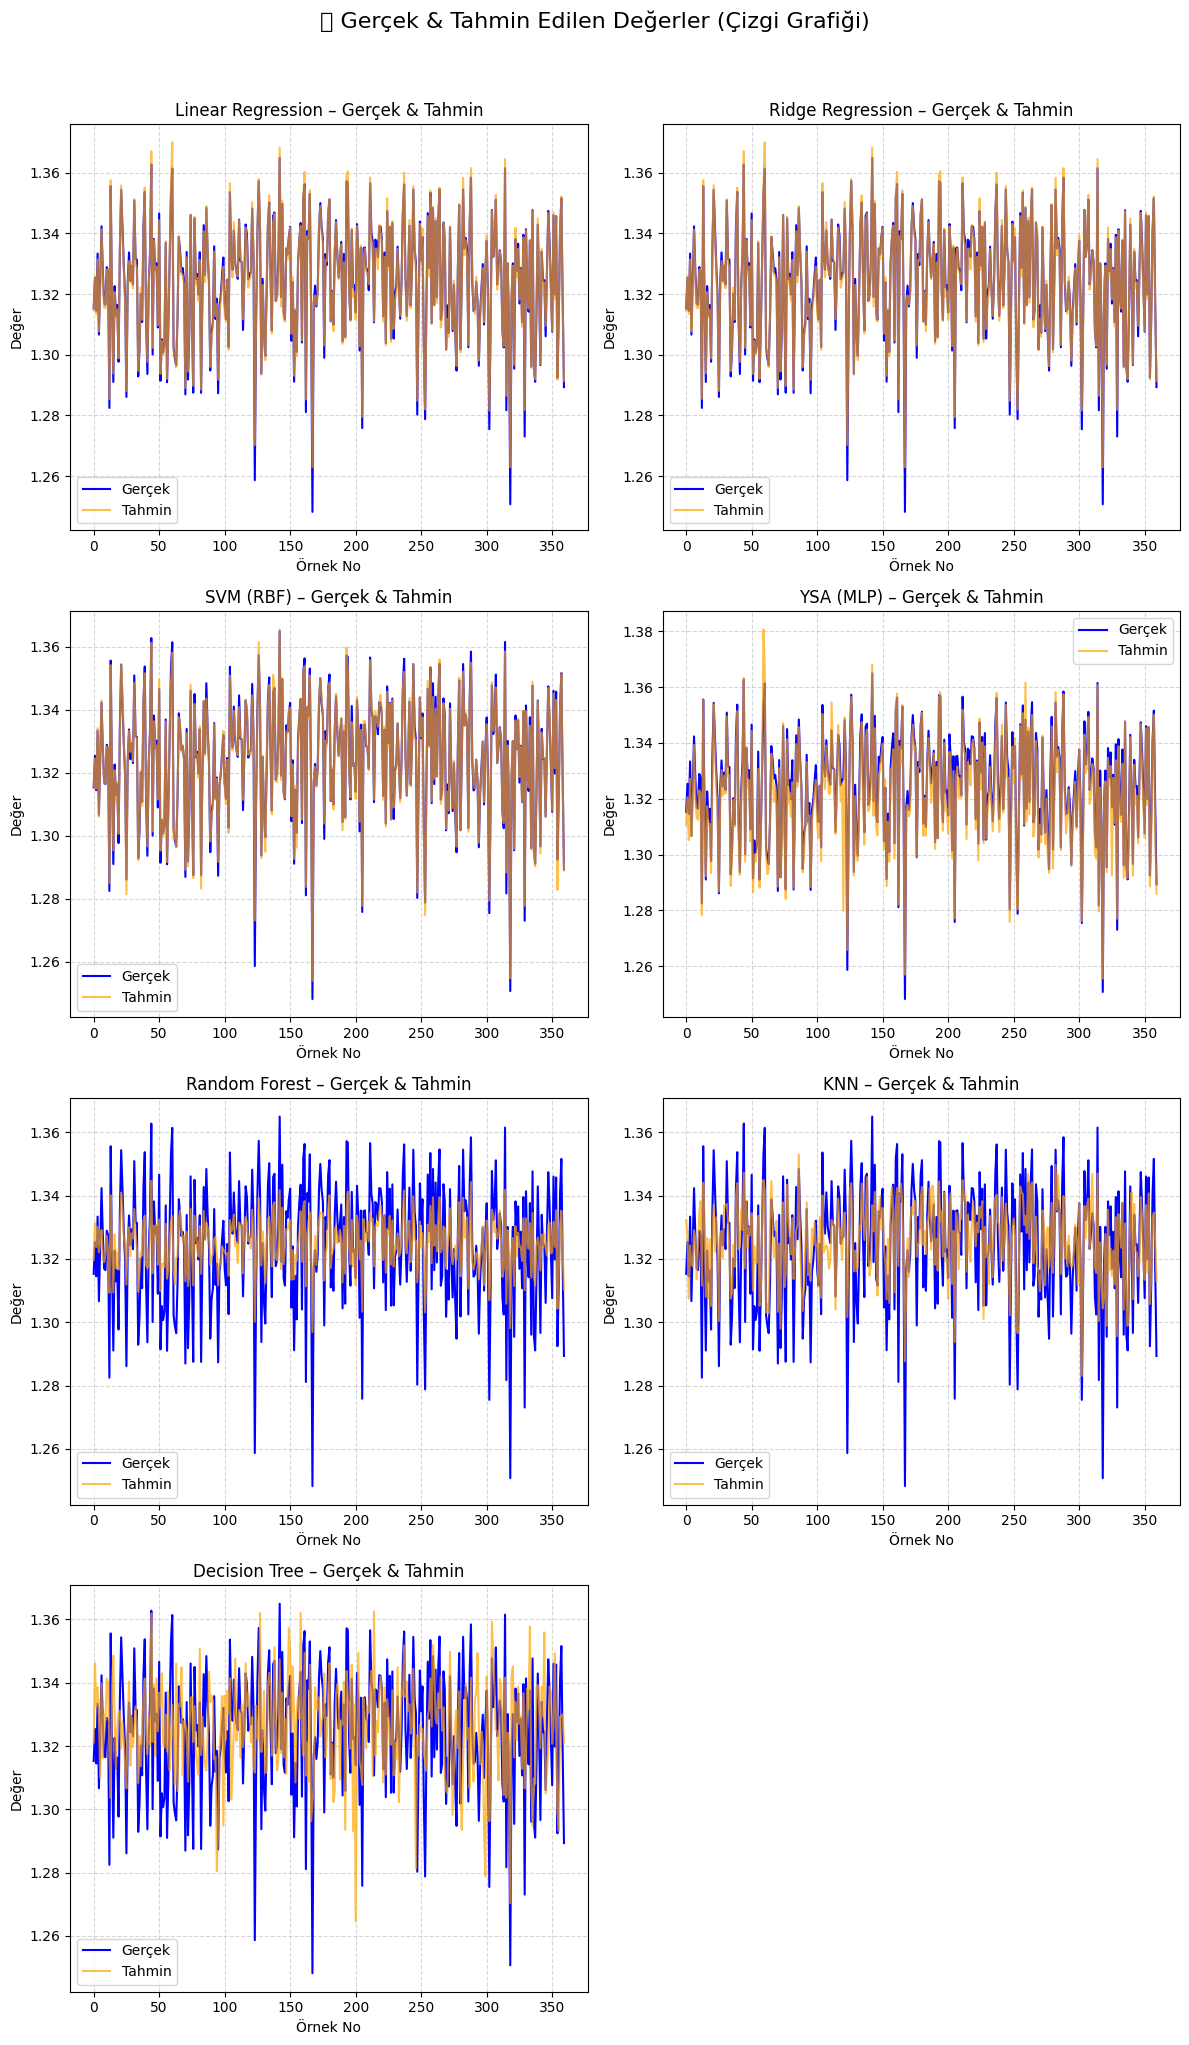

In [16]:

# ======================================
# 🔟 GÖRSEL 1: ÇİZGİ GRAFİĞİ (Gerçek & Tahmin)
# ======================================

# Gerçek değerleri diziye çevir
true_vals = np.asarray(y_test)

# Kaç model varsa ona göre subplot düzeni oluştur
n_models = len(predictions)
n_cols = 2
n_rows = (n_models + n_cols - 1) // n_cols  # tavana yuvarlama

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 5 * n_rows))

# axes tek satır/tek kolon durumlarında da düzgün çalışsın
axes = np.array(axes).reshape(-1)

for i, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[i]
    ax.plot(np.arange(len(true_vals)), true_vals, label="Gerçek", color="blue")
    ax.plot(np.arange(len(y_pred)), y_pred, label="Tahmin", color="orange", alpha=0.7)
    ax.set_title(f"{name} – Gerçek & Tahmin")
    ax.set_xlabel("Örnek No")
    ax.set_ylabel("Değer")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

# Kullanılmayan boş subplot varsa kaldır
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("🔹 Gerçek & Tahmin Edilen Değerler (Çizgi Grafiği)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3926/586053884.py:16: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


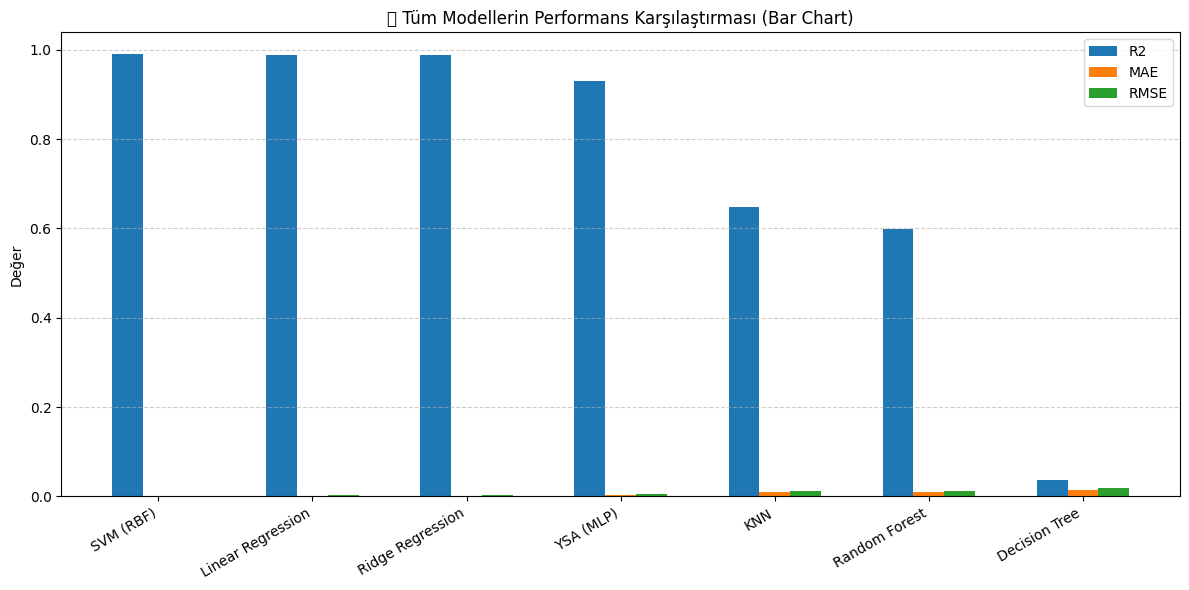

In [17]:

# ======================================
# 1️⃣1️⃣ GÖRSEL 2: BAR CHART (Performans Karşılaştırması)
# ======================================
metrics = ["R2", "MAE", "RMSE"]
x = np.arange(len(results_df["Model"]))
width = 0.2

plt.figure(figsize=(12, 6))
for i, metric in enumerate(metrics):
    plt.bar(x + i*width, results_df[metric], width=width, label=metric)
plt.xticks(x + width, results_df["Model"], rotation=30, ha="right")
plt.ylabel("Değer")
plt.title("🔹 Tüm Modellerin Performans Karşılaştırması (Bar Chart)")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3926/322356195.py:27: UserWarning: Glyph 128376 (\N{SPIDER WEB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128376 (\N{SPIDER WEB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


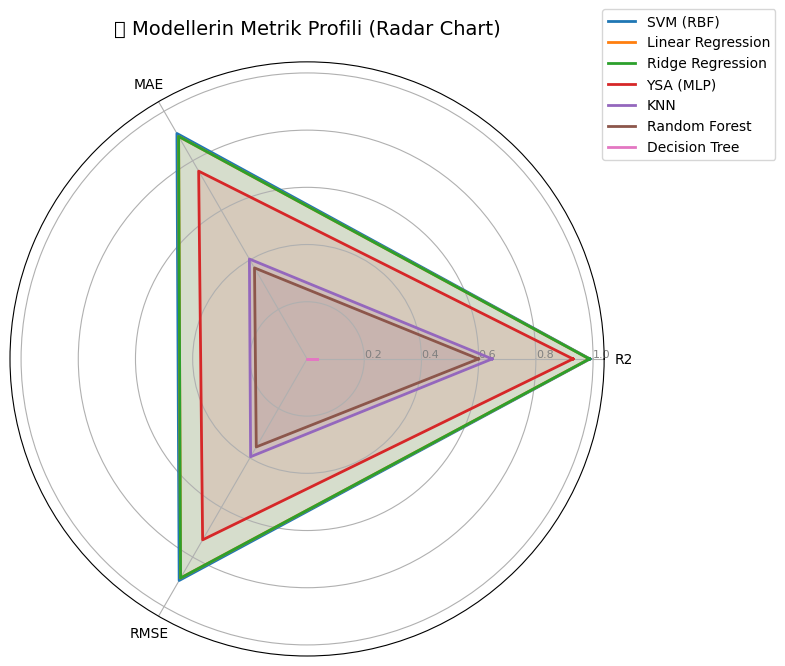

In [18]:

# ======================================
# 1️⃣2️⃣ GÖRSEL 3: RADAR CHART (Örümcek Grafiği)
# ======================================
from math import pi

metrics = ["R2", "MAE", "RMSE"]
N = len(metrics)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

for idx, row in results_df.iterrows():
    values = row[metrics].tolist()
    # MAE & RMSE küçük olması iyi olduğu için ters çevirelim (normalize görünüm için)
    values = [values[0], 1 - (values[1]/max(results_df["MAE"])), 1 - (values[2]/max(results_df["RMSE"]))]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=row["Model"])
    ax.fill(angles, values, alpha=0.1)

plt.xticks(angles[:-1], metrics)
ax.set_rlabel_position(0)
plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], color="gray", size=8)
plt.title("🕸️ Modellerin Metrik Profili (Radar Chart)", size=14, pad=20)
plt.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()


✅ En iyi model: SVM (RBF)
SVM (RBF) modeli ağaç tabanlı değil. Permutation importance hesaplanıyor...


/tmp/ipykernel_3926/2958642646.py:52: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128313 (\N{SMALL BLUE DIAMOND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


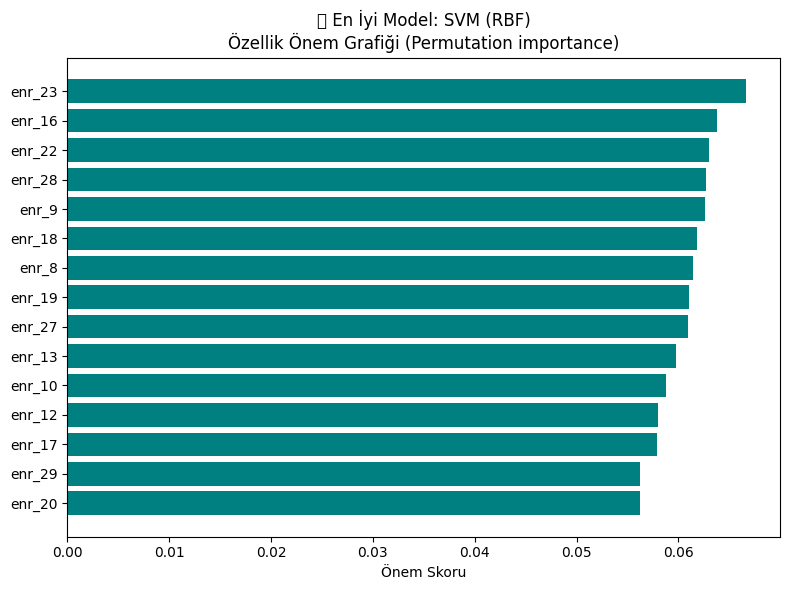

In [19]:
# ======================================
# 1️⃣3️⃣ EN İYİ MODELİN ÖZELLİK ÖNEMİ GRAFİĞİ
# ======================================
from sklearn.inspection import permutation_importance
import numpy as np
import matplotlib.pyplot as plt

# En iyi modeli R² değerine göre seçelim
best_model_name = results_df.iloc[0]["Model"]
print(f"✅ En iyi model: {best_model_name}")

best_model = models[best_model_name]

# Boru hattı (pipeline) ile eğitilmiş modeli yeniden kullanacağız
pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", best_model)])
pipe.fit(X_train, y_train)

# Özellik isimlerini al
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
all_features = list(num_cols)

# OneHotEncoder kullanıldıysa, yeni sütun isimlerini genişletelim
if len(cat_cols) > 0:
    try:
        cat_encoder = pipe.named_steps["preprocess"].named_transformers_["cat"].named_steps["onehot"]
        cat_features = cat_encoder.get_feature_names_out(cat_cols)
        all_features = list(num_cols) + list(cat_features)
    except Exception:
        pass

# Özellik önemlerini hesapla
if hasattr(best_model, "feature_importances_"):
    importance = best_model.feature_importances_
    method_used = "Tree-based feature_importances_"
else:
    print(f"{best_model_name} modeli ağaç tabanlı değil. Permutation importance hesaplanıyor...")
    result = permutation_importance(pipe, X_test, y_test, n_repeats=10, random_state=42)
    importance = result.importances_mean
    method_used = "Permutation importance"

# En önemli 15 özelliği seçelim
sorted_idx = np.argsort(importance)[::-1][:15]
top_features = np.array(all_features)[sorted_idx]
top_importance = importance[sorted_idx]

# Görselleştirme
plt.figure(figsize=(8,6))
plt.barh(top_features[::-1], top_importance[::-1], color="teal")
plt.xlabel("Önem Skoru")
plt.title(f"🔹 En İyi Model: {best_model_name}\nÖzellik Önem Grafiği ({method_used})")
plt.tight_layout()
plt.show()


In [ ]:
import shap
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt


if 'preprocessor' in locals():
    X_sample_proc = preprocessor.transform(X_test)
elif 'pipeline' in locals() and hasattr(pipeline, 'named_steps') and 'preprocessor' in pipeline.named_steps:
    X_sample_proc = pipeline.named_steps['preprocessor'].transform(X_test)
elif 'X_test' in locals():
    X_sample_proc = X_test
elif 'X' in locals():
    X_sample_proc = X
else:
    raise NameError("Не найдены переменные с признаками (X_test, X_train или X). Укажите нужную выборку вручную.")

print(f"✅ SHAP analizi yapılacak model: {best_model_name}")


if sp.issparse(X_sample_proc):
    X_sample_proc_dense = X_sample_proc.toarray()
else:
    X_sample_proc_dense = np.asarray(X_sample_proc)


X_to_plot = X_sample_proc_dense[:100]


tree_models = ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "Decision Tree", "Gradient Boosting", "Extra Trees"]
is_tree = any(t.lower() in best_model_name.lower() for t in tree_models)

if is_tree:
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_to_plot)
    print("SHAP yöntemi: TreeExplainer")
else:
    print(f"{best_model_name} modeli ağaç tabanlı değil. KernelExplainer kullanılıyor (biraz yavaş olabilir)...")
    background = shap.sample(X_to_plot, min(50, len(X_to_plot)))
    explainer = shap.KernelExplainer(best_model.predict, background)
    shap_values = explainer.shap_values(X_to_plot)
    print("SHAP yöntemi: KernelExplainer (approx)")


if isinstance(shap_values, list):
    shap_values = shap_values[0]
elif getattr(shap_values, "ndim", 0) == 3:
    shap_values = shap_values[:, :, 0]

X_to_plot = X_to_plot[:len(shap_values)]


plt.figure()
plt.title(f"SHAP Global Özellik Önem Grafiği ({best_model_name})")
shap.summary_plot(shap_values, X_to_plot, feature_names=all_features, show=True)


✅ SHAP analizi yapılacak model: SVM (RBF)
SVM (RBF) modeli ağaç tabanlı değil. KernelExplainer kullanılıyor (biraz yavaş olabilir)...


  0%|          | 0/100 [00:00<?, ?it/s]